In [1]:
import cv2
import numpy as np
import tensorflow as tf
import torch

print("cv2:", cv2.__version__)
print("numpy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)

cv2: 4.8.1
numpy: 1.23.5
TensorFlow: 2.12.0
PyTorch: 2.0.1+cpu


In [1]:
import cv2
import matplotlib.pyplot as plt

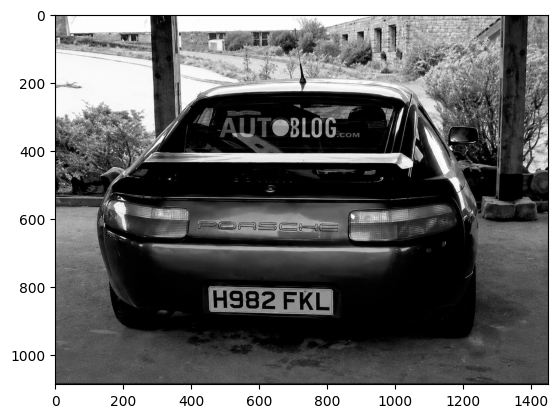

In [4]:
img=cv2.imread(r"C:\Users\anshu\OneDrive\Desktop\Car dataset (1)\mycar.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(cv2.cvtColor(gray,cv2.COLOR_BGR2RGB))

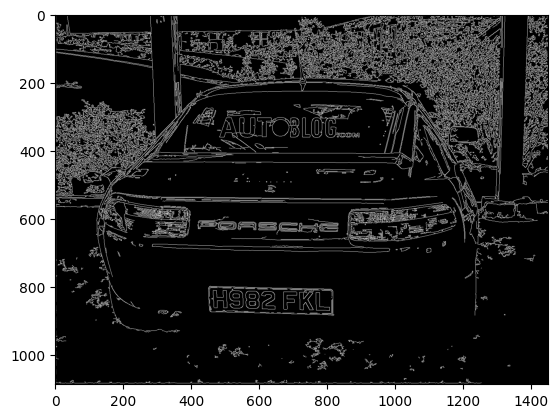

In [5]:
bfilter = cv2.bilateralFilter(gray , 4 , 7 , 7)
edged = cv2.Canny(bfilter,30 ,300)
plt.imshow(cv2.cvtColor(edged, cv2.COLOR_BGR2RGB))

In [6]:
import imutils
keypoints=cv2.findContours(edged.copy(),cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
contours = imutils.grab_contours(keypoints)
contours = sorted(contours , key =cv2.contourArea, reverse =True)[:10]

In [7]:
location = None
for contour in contours:
    approx=cv2.approxPolyDP(contour, 10,True)
    if len(approx)>=4:
        location=approx
        break


In [8]:
location

array([[[450, 804]],

       [[458, 874]],

       [[819, 883]],

       [[810, 807]]], dtype=int32)

In [9]:
import numpy as np
mask = np.zeros(gray.shape, np.uint8)
new_image=cv2.drawContours(mask,[location],0,255,-1)
new_image=cv2.bitwise_and(img,img,mask=mask)

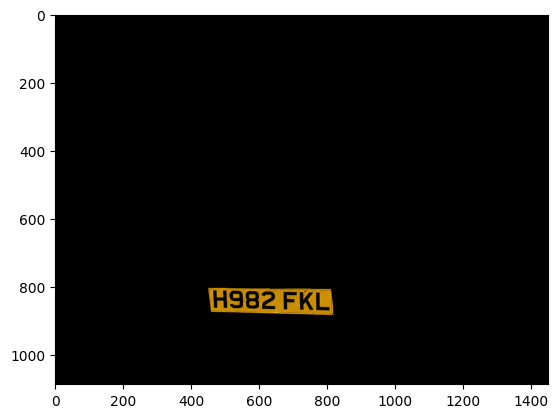

In [10]:
plt.imshow(cv2.cvtColor(new_image,cv2.COLOR_BGR2RGB))

In [11]:
(x,y) = np.where(mask==255)
(x1,y1)=(np.min(x),np.min(y))
(x2,y2)=(np.max(x),np.max(y))
cropped_image=gray[x1:x2+1,y1:y2+1]

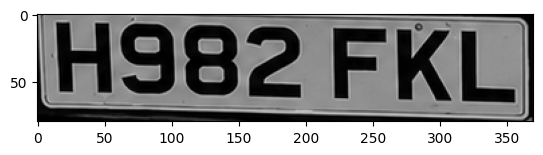

In [12]:
plt.imshow(cv2.cvtColor(cropped_image,cv2.COLOR_BGR2RGB))

In [13]:
import easyocr
reader = easyocr.Reader(['en'])
result = reader.readtext(cropped_image)
result

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.


[([[3, 0], [370, 0], [370, 80], [3, 80]], 'H98z FKL]', 0.719165439671419)]

H98z FKL]


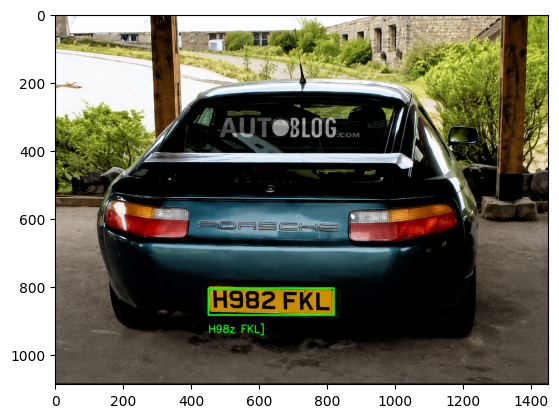

In [14]:
text=result[0][-2]
font=cv2.FONT_HERSHEY_SIMPLEX
res=cv2.putText(img,text=text,org=(approx[0][0][0],approx[1][0][1]+60), fontFace=font,fontScale=1,color=(0,255,0),thickness=2,lineType=cv2.LINE_AA)
res=cv2.rectangle(img,tuple(approx[0][0]),tuple(approx[2][0]),(0,255,0),3)
plt.imshow(cv2.cvtColor(res,cv2.COLOR_BGR2RGB))

print(text)